# 01 · Подготовка UCI и более строгие группы

## tl;dr

Старые части UCI разделяли файлы, но 38 групп префиксов пересекали train/validation/test. Новая нормализация даёт 177 консервативных групп. Файл и префикс не являются подтверждённым ID пациентки. Первичные данные сохраняются; основная оценка теперь по повторным групповым фолдам.


## Context & Methods
### Key Assumptions
Нормализация имён консервативна: буквенный initials-like префикс объединяется, S+цифры остаются самостоятельными кодами; регистр игнорируется. Дополнительно объединяются feature-identical группы. Это снижает риск зависимых источников, не восстанавливает истинные patient IDs. Все распределения ниже описательны на уже известном источнике.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · первичная таблица и роли полей

In [5]:
from src.training.ctg_review_evidence import uci_groups
from src.features.ctg_preprocessing import CTG_FEATURES
d=uci_groups();x=d[list(CTG_FEATURES)]
assert len(d)==2126 and x.notna().all().all()
print('Сегментов:',len(d),'файлов:',d.source_file.nunique(),'групп-прокси:',d.review_group.nunique())
display(pd.DataFrame({'dtype':x.dtypes.astype(str),'missing':x.isna().sum(),'zeros':(x==0).sum(),'unique':x.nunique()}))
display(d.groupby('NSP').agg(segments=('NSP','size'),files=('source_file','nunique'),proxy_groups=('review_group','nunique')))
destination=ROOT/'data/processed/ctg_uci/reviewed_v3';destination.mkdir(exist_ok=True)
d.to_parquet(destination/'ctg_primary_grouped.parquet',index=False)


Сегментов: 2126 файлов: 352 групп-прокси: 177


,dtype,missing,zeros,unique
LB,float64,0,0,48
AC,float64,0,891,1015
FM,float64,0,1311,696
UC,float64,0,332,1315
DL,float64,0,1231,751
DS,float64,0,2119,8
DP,float64,0,1948,166
ASTV,float64,0,0,75
MSTV,float64,0,0,57
ALTV,float64,0,1240,87


,segments,files,proxy_groups
NSP,,,
1,1655,275,167
2,295,123,56
3,176,50,35


## Results · распределения и закодированная категория

Tendency — категория -1/0/1. DS константа; Width=Max-Min, исключаются моделью как избыточные.


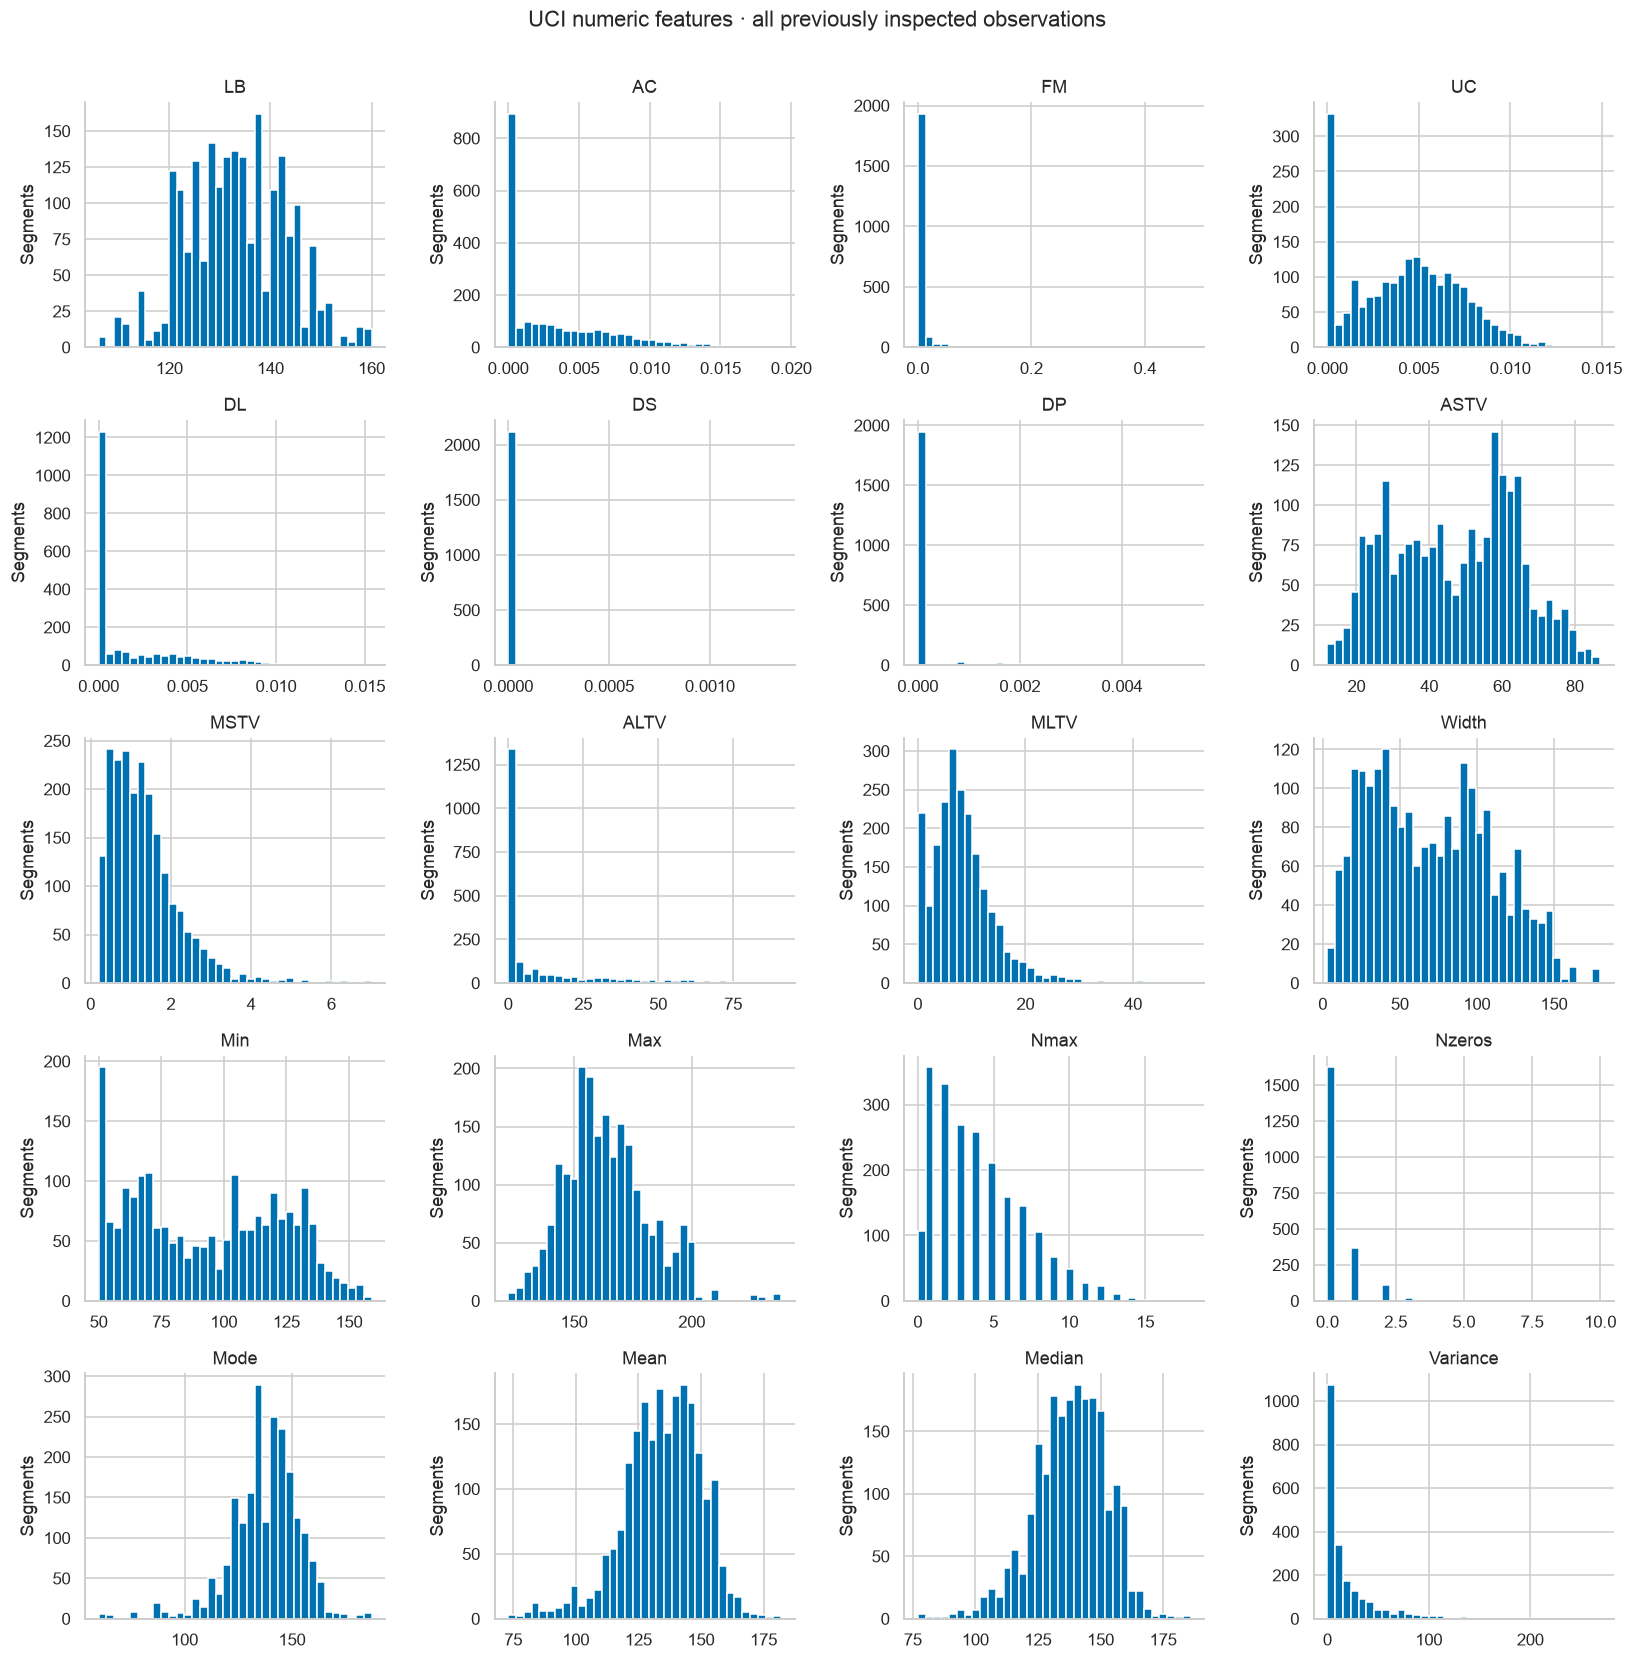

,segments
Tendency,
-1,165
0,1115
1,846


In [7]:
numeric=[c for c in CTG_FEATURES if c!='Tendency']
fig,axes=plt.subplots(5,4,figsize=(15,15))
for ax,col in zip(axes.flat,numeric):
    ax.hist(x[col],bins=35,color='#0072b2');ax.set(title=col,ylabel='Segments')
fig.suptitle('UCI numeric features · all previously inspected observations',y=1.005)
fig.tight_layout();save_show('uci01_feature_distributions.png')
display(x.Tendency.value_counts().sort_index().rename('segments').to_frame())
print('Tendency — категория -1/0/1. DS константа; Width=Max-Min, исключаются моделью как избыточные.')


### Зависимость источников и прежний test

,value
records,2126
source_files,352
prefix_proxies,177
merged_review_groups,177
proxy_groups_crossing_old_splits,38
old_test_records,425
old_test_path_segments,35
old_test_path_files,10
old_test_path_proxy_groups,8
old_test_path_files_shared_prefix_train,7


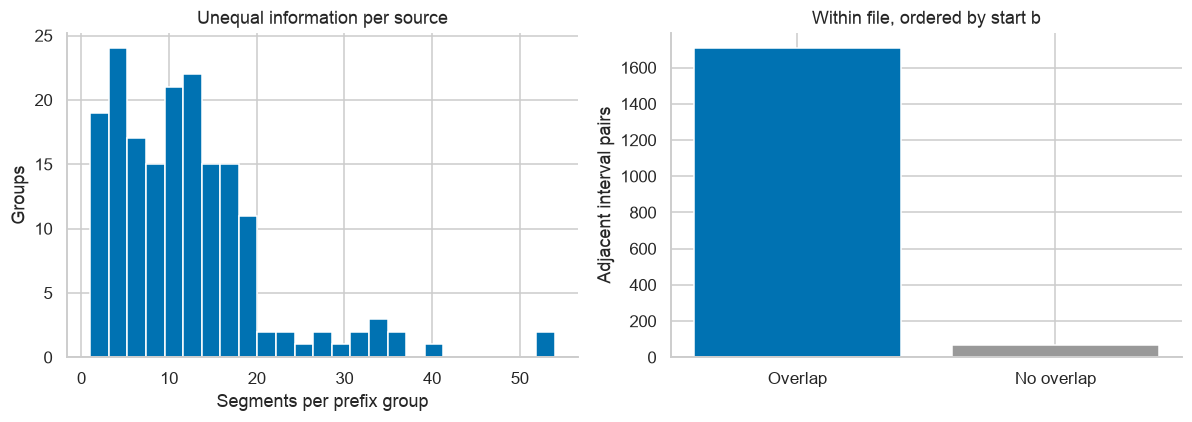

In [9]:
claims=json.loads((REVIEW/'uci_claims.json').read_text());display(pd.Series(claims).to_frame('value'))
support=pd.read_csv(REVIEW/'uci_proxy_group_support.csv')
overlap=pd.read_csv(REVIEW/'uci_adjacent_interval_overlap.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(support.segments,bins=25,color='#0072b2');axes[0].set(xlabel='Segments per prefix group',ylabel='Groups',title='Unequal information per source')
axes[1].bar(['Overlap','No overlap'],[overlap.overlaps.sum(),(~overlap.overlaps).sum()],color=['#0072b2','#999999'])
axes[1].set(ylabel='Adjacent interval pairs',title='Within file, ordered by start b');axes[1].set_ylim(bottom=0)
fig.tight_layout();save_show('uci01_group_dependence.png')


### Подготовка внутри CV
Скейлеры fit только на текущей fit-части в 02. Пропусков в исходной UCI нет: новый неполный native-вход отклоняется. Готового X_scaled по всей базе для CV нет. Порядок и схема входов проверяются CTGInputGuard; Tendency кодируется как категория. Отдельный fitted logistic preprocessor сохраняется после итогового обучения.


## Takeaways

UCI используется как benchmark экспертных классов. Префикс — прокси независимого источника, не подтверждённый ID пациентки. Все данные ранее просмотрены: эта ревизия оценивает исправленную процедуру на повторной nested CV, без нового blind-test заявления. Полный разбор 23 замечаний — в [07](07_deep_audit_and_recommendations.ipynb).
